# Tarea2 Parte 1: Segmentación de imágenes con Mean-Shift
Sebastian Diaz,
Julian Zavala

Algoritmo `cv2.pyrMeanShiftFiltering` de OpenCV.

## 1. Importación de librerías y configuración

In [9]:
import time
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(42)

# Mostrar las figuras dentro del notebook
%matplotlib inline

## 2. Carga y preprocesamiento de imágenes

### Descarga de imagenes
Esta celda descarga `img1.jpg`, `img2.jpg` e `img3.jpg` desde el repositorio si no estan presentes, para ejecutar el notebook sin subirlas manualmente.

In [10]:
import urllib.request

REPO_RAW = "https://raw.githubusercontent.com/sebcld/tarea2-IA/main"
for _img in ["img1.jpg", "img2.jpg", "img3.jpg"]:
    if os.path.exists(_img):
        print(_img, "ya existe; no se descarga.")
    else:
        _url = f"{REPO_RAW}/{_img}"
        urllib.request.urlretrieve(_url, _img)
        print("Descargada:", _img)

Descargada: img1.jpg
Descargada: img2.jpg
Descargada: img3.jpg


In [11]:
EXTENSION = ".jpg"
nombres_archivos = [f"img1{EXTENSION}", f"img2{EXTENSION}", f"img3{EXTENSION}"]

ANCHO_MAXIMO = 500


def cargar_y_redimensionar(ruta, ancho_max=ANCHO_MAXIMO):

    img_bgr = cv2.imread(ruta)
    if img_bgr is None:
        raise FileNotFoundError(
            f"No se pudo cargar '{ruta}'. Revisar el nombre/extensión (variable EXTENSION)."
        )
    alto, ancho = img_bgr.shape[:2]
    if ancho > ancho_max:
        escala = ancho_max / ancho
        nuevo_tam = (ancho_max, int(round(alto * escala)))
        img_bgr = cv2.resize(img_bgr, nuevo_tam, interpolation=cv2.INTER_AREA)
    return img_bgr


imagenes_bgr = [cargar_y_redimensionar(n) for n in nombres_archivos]

imagenes_rgb = [cv2.cvtColor(img, cv2.COLOR_BGR2RGB) for img in imagenes_bgr]

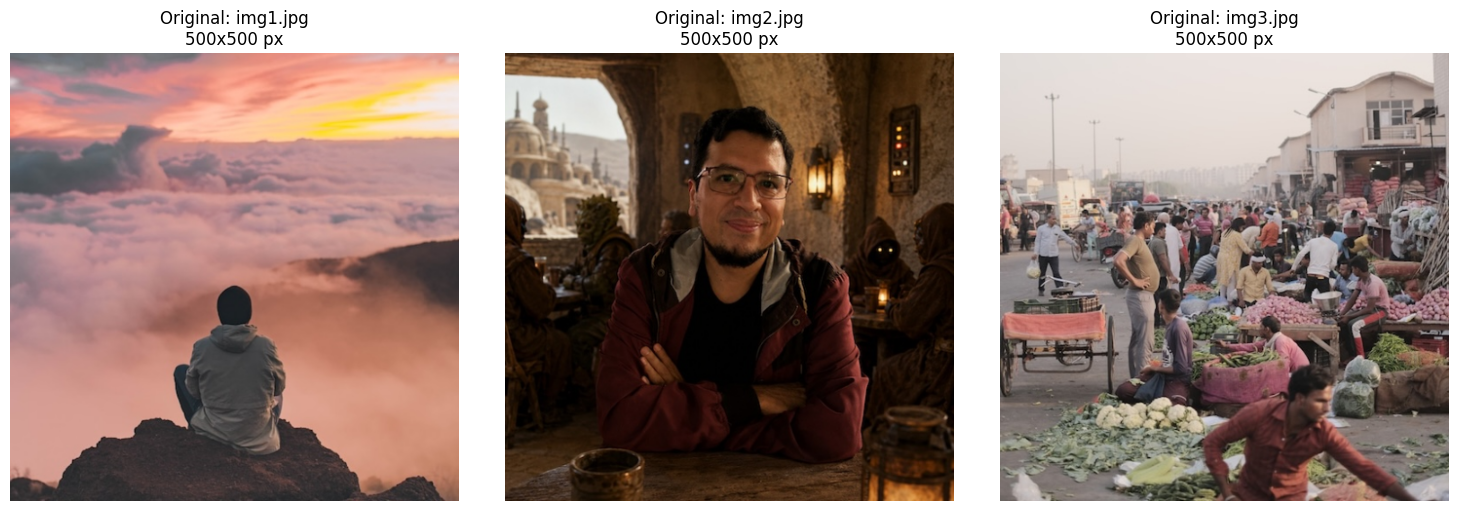

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img_rgb, nombre in zip(axes, imagenes_rgb, nombres_archivos):
    ax.imshow(img_rgb)
    ax.set_title(f"Original: {nombre}\n{img_rgb.shape[1]}x{img_rgb.shape[0]} px")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Función auxiliar: filtrado Mean-Shift

In [13]:
def aplicar_mean_shift(src, sp, sr, maxLevel=1):
    return cv2.pyrMeanShiftFiltering(src, sp, sr, maxLevel=maxLevel)

## 4. Función auxiliar: conteo de colores únicos

In [14]:
def contar_colores_unicos(img):
    pixeles = img.reshape(-1, img.shape[2])
    colores_unicos = np.unique(pixeles, axis=0)
    return int(colores_unicos.shape[0])

## 5. cuadros de parámetros

In [15]:
sp_valores = [10, 20, 40]
sr_valores = [10, 40, 60]
maxLevel_valores = [0, 1]

# total de combinaciones por imagen: 3 (sp) x 3 (sr) x 2 (maxLevel) = 18

## 6. Procesamiento y visualizacion lado a lado (18 combinaciones por imagen)

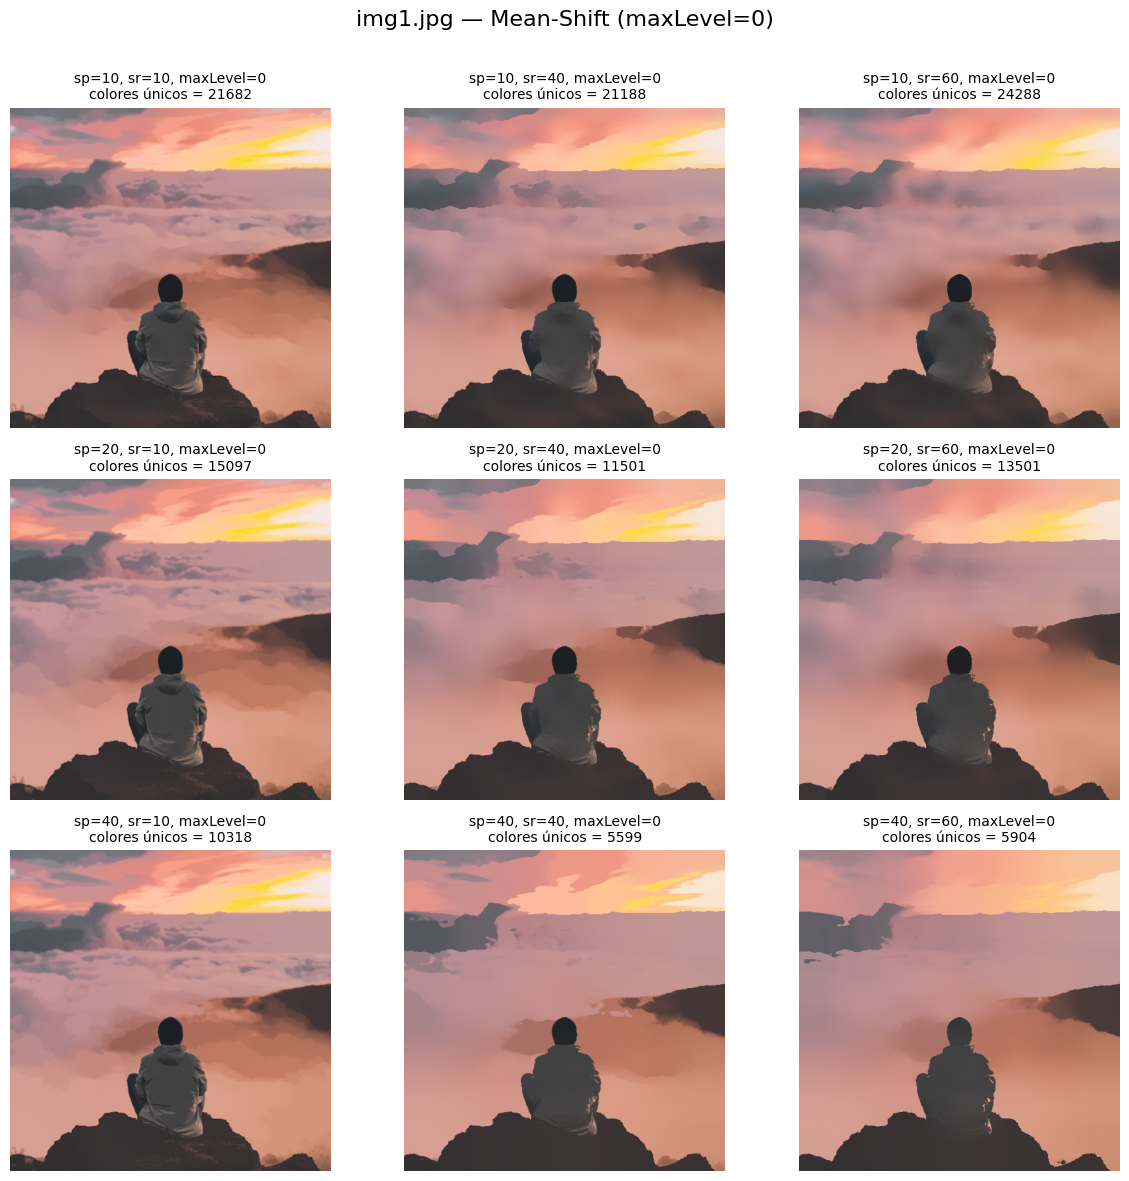

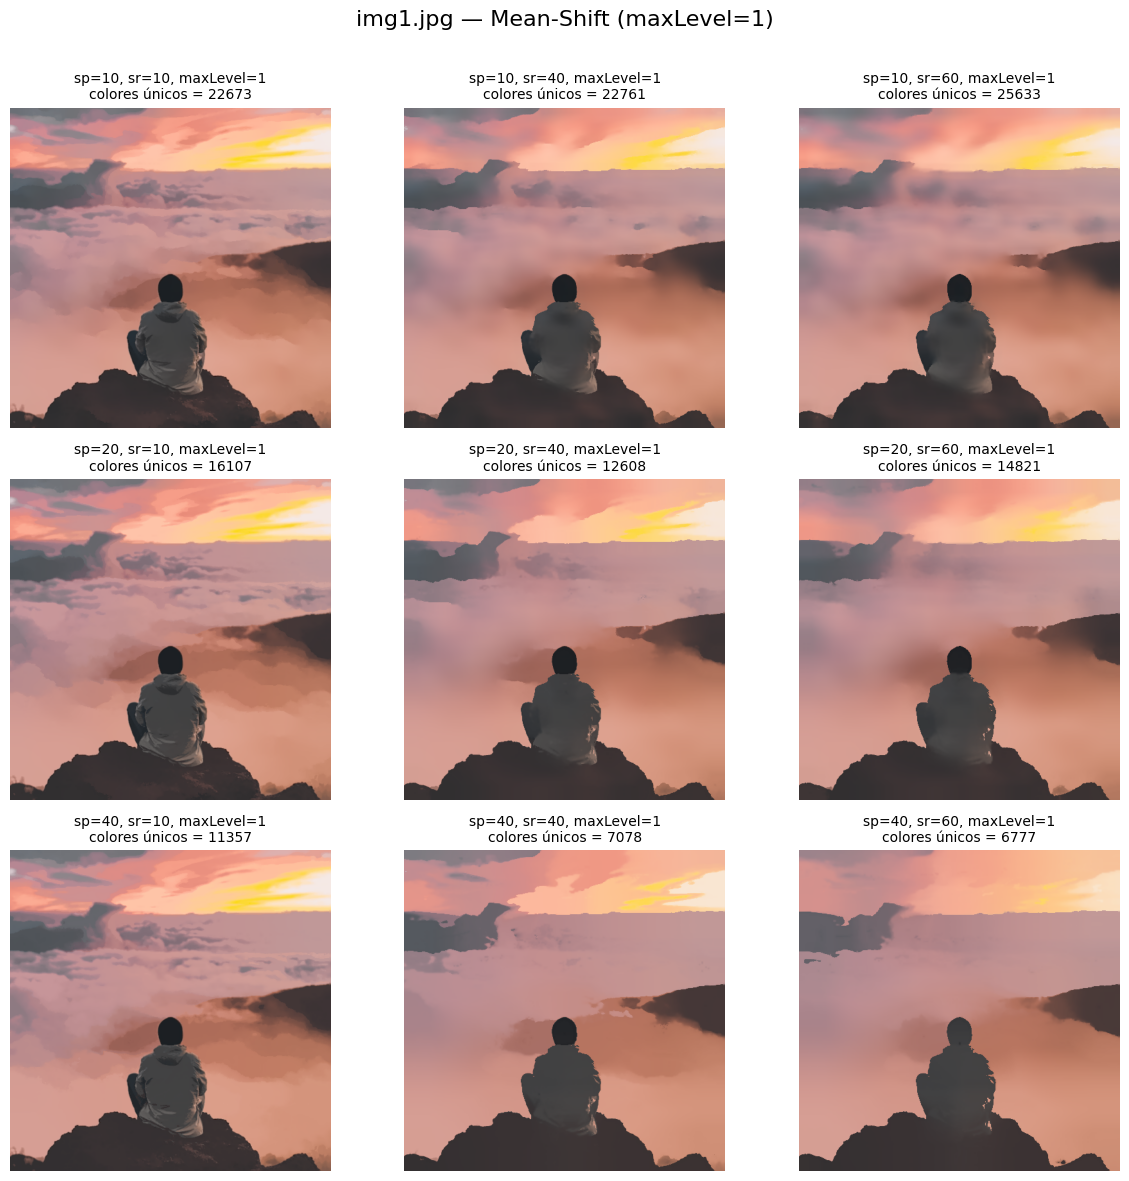

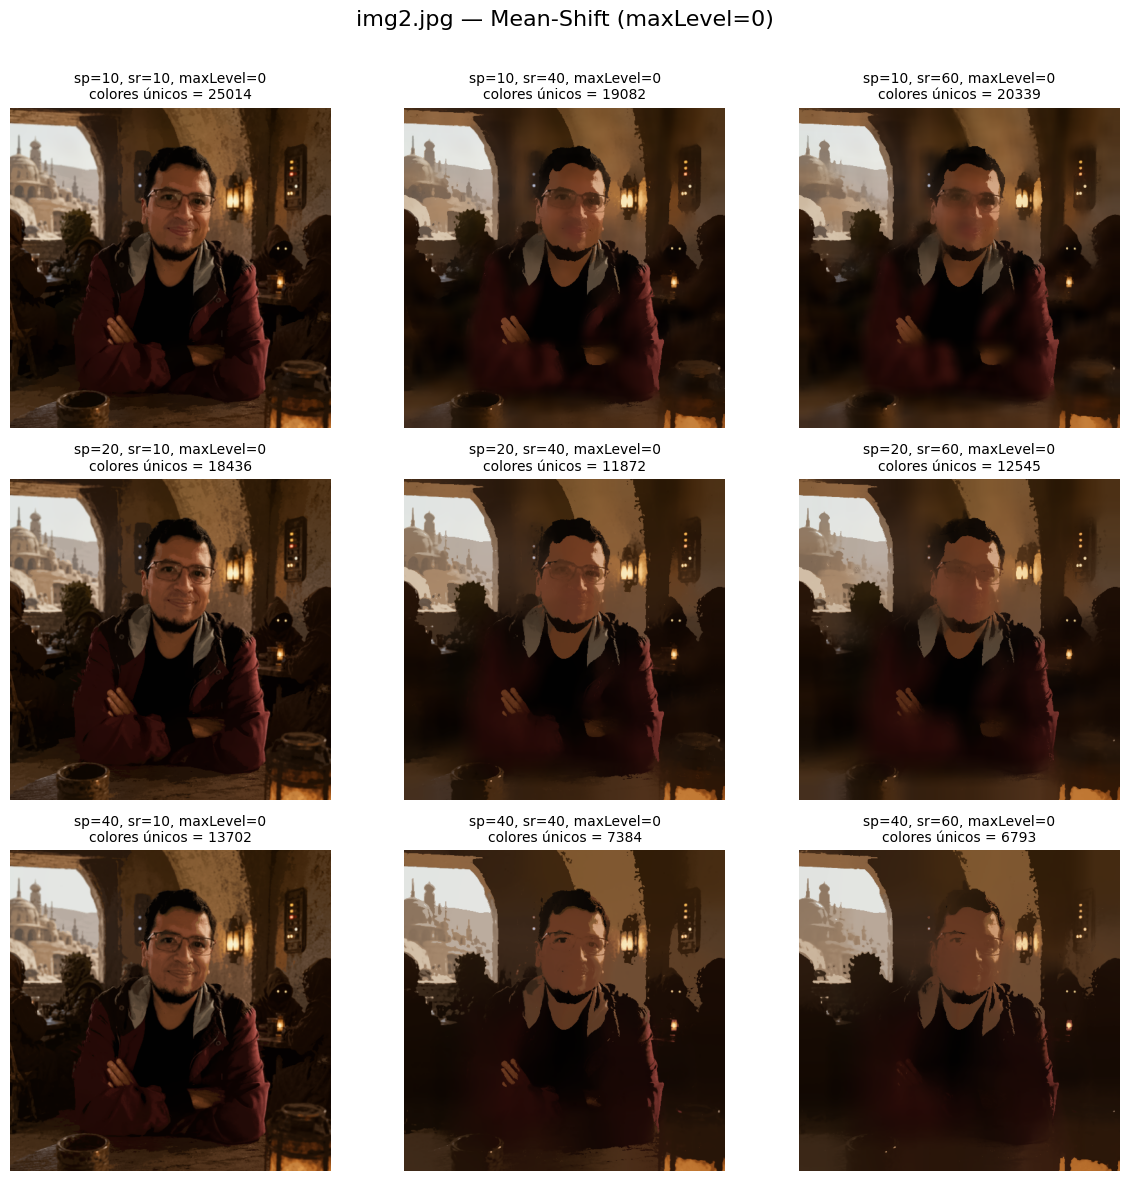

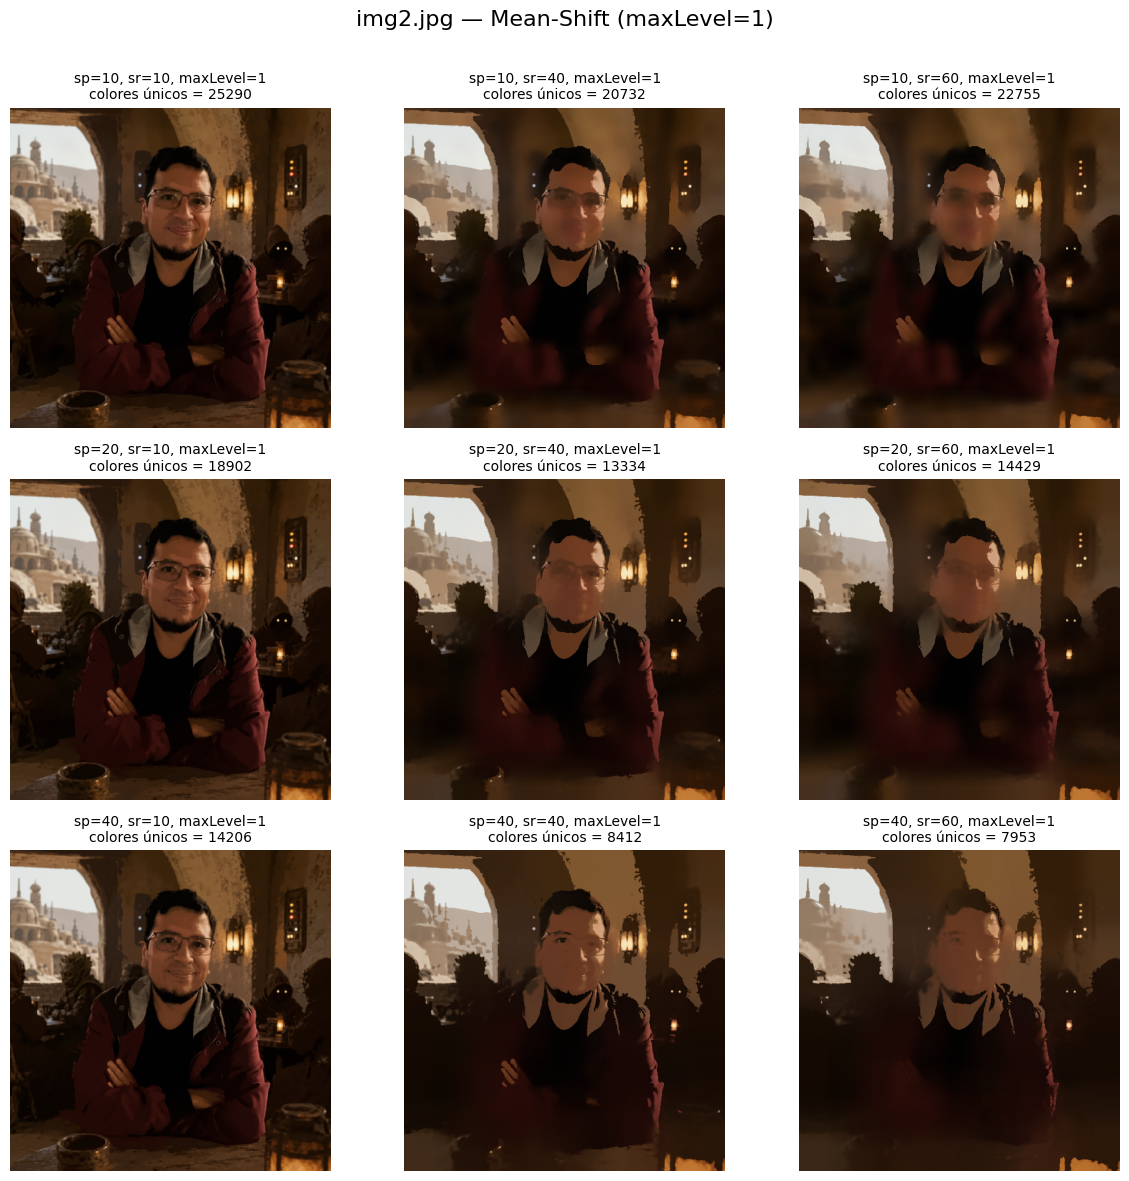

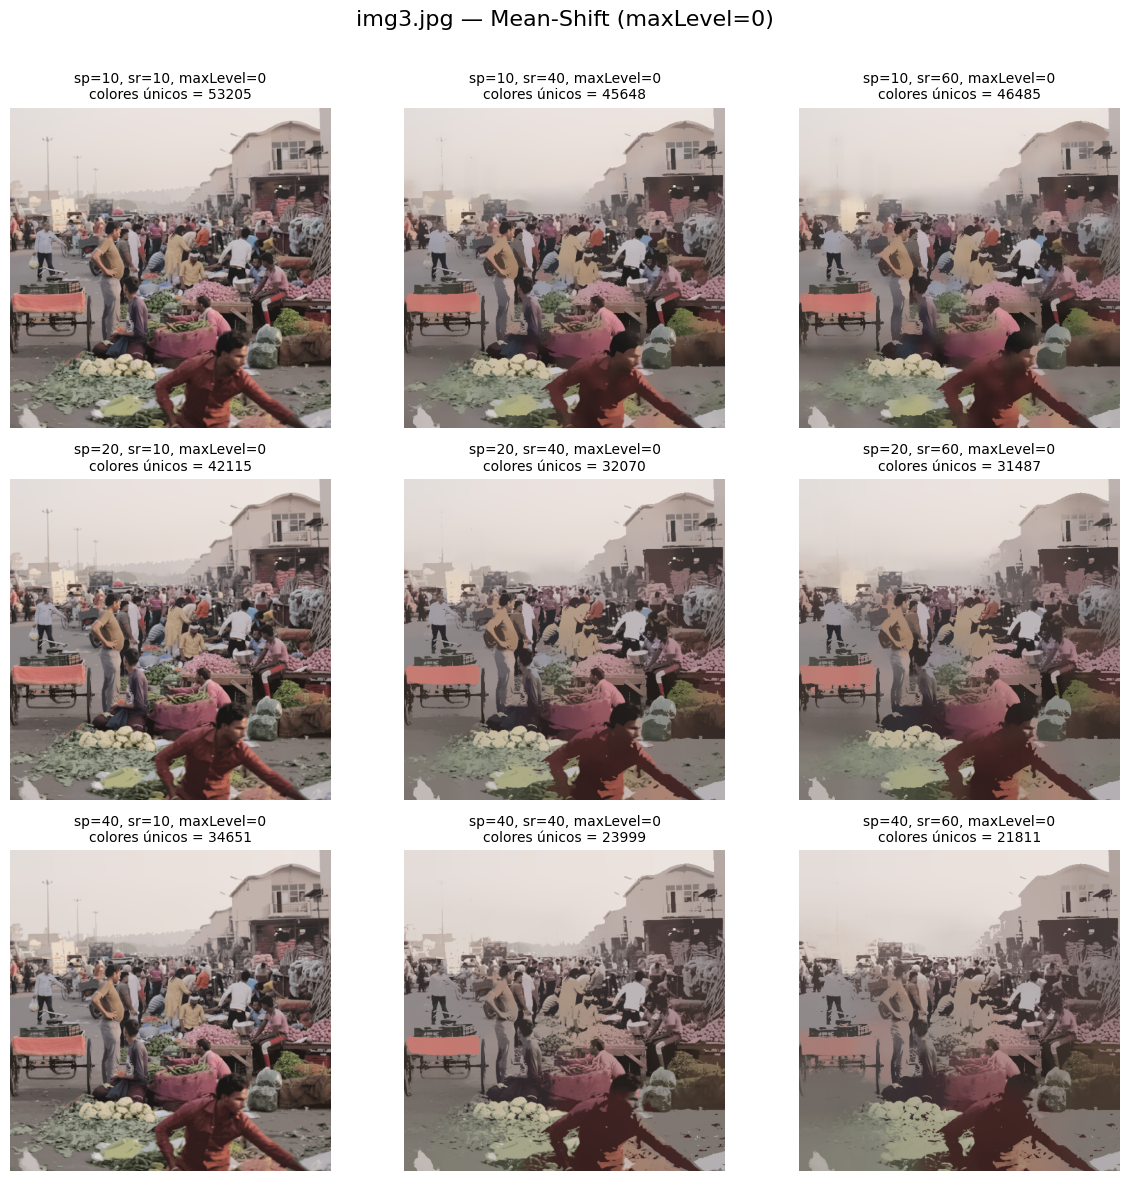

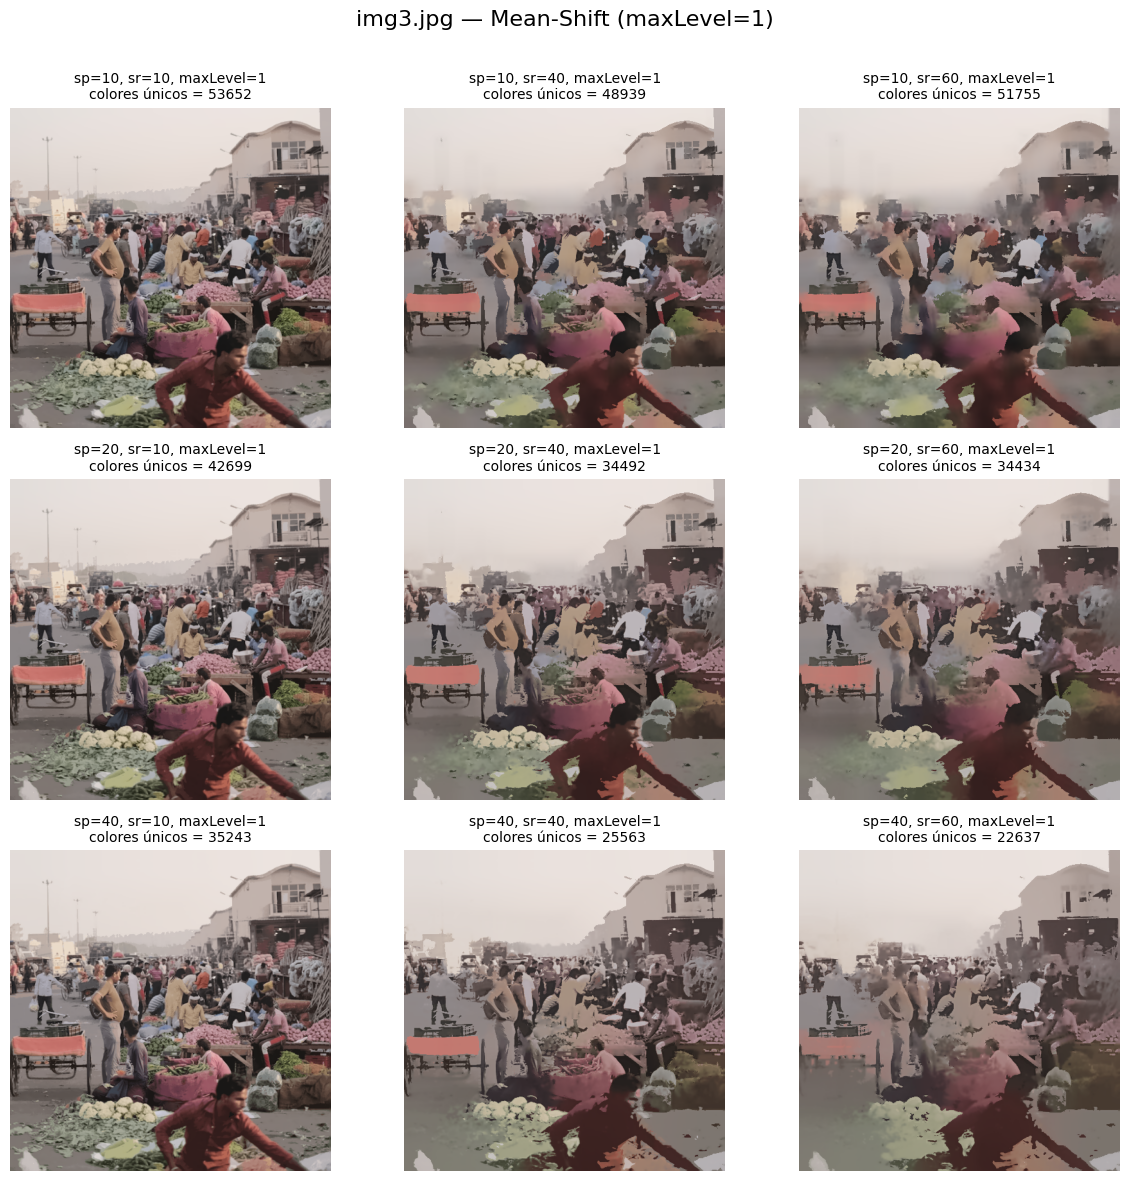

In [16]:
tablas_por_imagen = {}
tiempos_por_imagen = {}

for img_bgr, nombre in zip(imagenes_bgr, nombres_archivos):

    resultados = {}
    filas_tabla = []
    tiempos = {0: 0.0, 1: 0.0}   #
    for maxLevel in maxLevel_valores:
        for sp in sp_valores:
            for sr in sr_valores:
                inicio = time.perf_counter()
                filtrada_bgr = aplicar_mean_shift(img_bgr, sp, sr, maxLevel=maxLevel)
                tiempos[maxLevel] += time.perf_counter() - inicio

                n_colores = contar_colores_unicos(filtrada_bgr)
                filtrada_rgb = cv2.cvtColor(filtrada_bgr, cv2.COLOR_BGR2RGB)
                resultados[(sp, sr, maxLevel)] = (filtrada_rgb, n_colores)
                filas_tabla.append({
                    "sp": sp,
                    "sr": sr,
                    "maxLevel": maxLevel,
                    "n_colores_unicos": n_colores,
                })

    for maxLevel in maxLevel_valores:
        fig, axes = plt.subplots(3, 3, figsize=(12, 12))
        fig.suptitle(f"{nombre} — Mean-Shift (maxLevel={maxLevel})", fontsize=16)
        for i, sp in enumerate(sp_valores):        # filas -> sp
            for j, sr in enumerate(sr_valores):    # columnas -> sr
                filtrada_rgb, n_colores = resultados[(sp, sr, maxLevel)]
                ax = axes[i, j]
                ax.imshow(filtrada_rgb)
                ax.set_title(
                    f"sp={sp}, sr={sr}, maxLevel={maxLevel}\n"
                    f"colores únicos = {n_colores}",
                    fontsize=10,
                )
                ax.axis("off")
        plt.tight_layout(rect=[0, 0, 1, 0.97])
        plt.show()

    tabla = pd.DataFrame(
        filas_tabla, columns=["sp", "sr", "maxLevel", "n_colores_unicos"]
    )
    tablas_por_imagen[nombre] = tabla
    tiempos_por_imagen[nombre] = tiempos

## 7. Tablas de variabilidad por imagen

In [17]:
print(f"Tabla de variabilidad — {nombres_archivos[0]}")
tablas_por_imagen[nombres_archivos[0]]

Tabla de variabilidad — img1.jpg


,sp,sr,maxLevel,n_colores_unicos
0,10,10,0,21682
1,10,40,0,21188
2,10,60,0,24288
3,20,10,0,15097
4,20,40,0,11501
5,20,60,0,13501
6,40,10,0,10318
7,40,40,0,5599
8,40,60,0,5904
9,10,10,1,22673


In [18]:
print(f"Tabla de variabilidad — {nombres_archivos[1]}")
tablas_por_imagen[nombres_archivos[1]]

Tabla de variabilidad — img2.jpg


,sp,sr,maxLevel,n_colores_unicos
0,10,10,0,25014
1,10,40,0,19082
2,10,60,0,20339
3,20,10,0,18436
4,20,40,0,11872
5,20,60,0,12545
6,40,10,0,13702
7,40,40,0,7384
8,40,60,0,6793
9,10,10,1,25290


In [19]:
print(f"Tabla de variabilidad — {nombres_archivos[2]}")
tablas_por_imagen[nombres_archivos[2]]

Tabla de variabilidad — img3.jpg


,sp,sr,maxLevel,n_colores_unicos
0,10,10,0,53205
1,10,40,0,45648
2,10,60,0,46485
3,20,10,0,42115
4,20,40,0,32070
5,20,60,0,31487
6,40,10,0,34651
7,40,40,0,23999
8,40,60,0,21811
9,10,10,1,53652


## 8. Comparación de tiempos de ejecución (maxLevel=0 vs maxLevel=1)

Tiempo total de cv2.pyrMeanShiftFiltering por imagen (9 combinaciones sp x sr en cada maxLevel):

  img1.jpg: maxLevel=0 = 68.16 s | maxLevel=1 = 18.65 s | maxLevel=0 tarda 49.51 s más (3.65x)
  img2.jpg: maxLevel=0 = 80.50 s | maxLevel=1 = 30.09 s | maxLevel=0 tarda 50.41 s más (2.68x)
  img3.jpg: maxLevel=0 = 88.26 s | maxLevel=1 = 45.25 s | maxLevel=0 tarda 43.01 s más (1.95x)


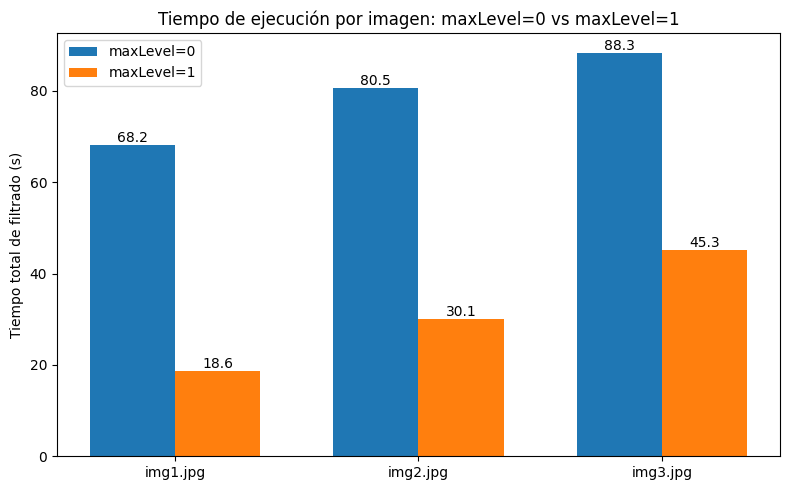

,imagen,t_maxLevel_0 (s),t_maxLevel_1 (s),diferencia_0_menos_1 (s),maxLevel_0 / maxLevel_1 (x)
0,img1.jpg,68.160,18.650,49.510,3.65
1,img2.jpg,80.502,30.092,50.410,2.68
2,img3.jpg,88.258,45.253,43.005,1.95


In [20]:
filas_tiempos = []
for nombre in nombres_archivos:
    t0 = tiempos_por_imagen[nombre][0]
    t1 = tiempos_por_imagen[nombre][1]
    diferencia = t0 - t1
    veces = t0 / t1 if t1 > 0 else float("nan")
    filas_tiempos.append({
        "imagen": nombre,
        "t_maxLevel_0 (s)": round(t0, 3),
        "t_maxLevel_1 (s)": round(t1, 3),
        "diferencia_0_menos_1 (s)": round(diferencia, 3),
        "maxLevel_0 / maxLevel_1 (x)": round(veces, 2),
    })

tabla_tiempos = pd.DataFrame(filas_tiempos)

# Resumen por consola
print("Tiempo total de cv2.pyrMeanShiftFiltering por imagen "
      "(9 combinaciones sp x sr en cada maxLevel):\n")
for f in filas_tiempos:
    print(f"  {f['imagen']}: maxLevel=0 = {f['t_maxLevel_0 (s)']:.2f} s | "
          f"maxLevel=1 = {f['t_maxLevel_1 (s)']:.2f} s | "
          f"maxLevel=0 tarda {f['diferencia_0_menos_1 (s)']:.2f} s más "
          f"({f['maxLevel_0 / maxLevel_1 (x)']:.2f}x)")

# Comparación visual: barras agrupadas por imagen
x = np.arange(len(nombres_archivos))
ancho = 0.35
t0s = [tiempos_por_imagen[n][0] for n in nombres_archivos]
t1s = [tiempos_por_imagen[n][1] for n in nombres_archivos]
fig, ax = plt.subplots(figsize=(8, 5))
b0 = ax.bar(x - ancho / 2, t0s, ancho, label="maxLevel=0")
b1 = ax.bar(x + ancho / 2, t1s, ancho, label="maxLevel=1")
ax.set_xticks(x)
ax.set_xticklabels(nombres_archivos)
ax.set_ylabel("Tiempo total de filtrado (s)")
ax.set_title("Tiempo de ejecución por imagen: maxLevel=0 vs maxLevel=1")
ax.bar_label(b0, fmt="%.1f")
ax.bar_label(b1, fmt="%.1f")
ax.legend()
plt.tight_layout()
plt.show()

tabla_tiempos

### 9.2 Efecto de cada parámetro

Para medir cuantitativamente el nivel de segmentación se utilizó el **número de colores únicos** presentes en cada imagen. En este caso, una menor cantidad de colores indica una mayor simplificación visual.

El parámetro con mayor impacto fue **`sp`**. Al aumentar su valor de 10 a 40, el número de colores únicos disminuyó de forma clara en las tres imágenes. Promediando sobre los valores de `sr` con `maxLevel=0`, la reducción fue de **68 %** en img1, **57 %** en img2 y **45 %** en img3. Visualmente, esto se traduce en una mayor pérdida de detalle: por ejemplo, el cielo de img1 se vuelve más plano y en img3 las personas lejanas y las verduras tienden a mezclarse en zonas menos definidas.

El parámetro **`sr`** también afecta el resultado, pero su comportamiento depende del valor de `sp`. Con `sp` bajo, aumentar `sr` no siempre reduce la cantidad de colores; incluso puede aumentarla, como ocurre en img1 con `sp=10`. En cambio, con `sp` alto, un mayor `sr` sí tiende a simplificar más la imagen. En términos visuales, valores altos de `sr` aplanan los colores y los acercan a los tonos dominantes, lo que puede provocar pérdida de rasgos o detalles, como se observa en img2.

Por último, **`maxLevel`** tuvo un efecto menor, pero consistente. Para los mismos valores de `(sp, sr)`, `maxLevel=1` produjo siempre una cantidad levemente mayor de colores únicos que `maxLevel=0`. Esto se debe al reescalado e interpolación, que generan colores intermedios en los bordes. Sin embargo, la diferencia visual fue casi imperceptible, por lo que su principal ventaja está en la **velocidad de procesamiento**, ya que `maxLevel=1` fue considerablemente más rápido sin afectar de forma relevante la calidad del resultado.

## 10. Mejor configuración

Se seleccionó en cada imagen la configuración con mayor simplificación que **conserva la estructura reconocible** de la escena. En las tres se eligió `maxLevel=0` porque respeta mejor los bordes; es una decisión que prioriza la **calidad sobre la velocidad**, ya que —como muestra la comparación de tiempos de la sección 8— `maxLevel=0` resultó claramente más lento que `maxLevel=1` (del orden del doble o más a esta resolución). Aun así, al tratarse de imágenes pequeñas (≤500 px), ese sobrecosto es asumible y queda compensado por unos bordes más fieles.

| Imagen | Mejor configuración | Colores únicos | Justificación |
|---|---|---|---|
| **img1** (simple) | `sp=40, sr=40, maxLevel=0` | 5.599 | Máxima simplificación que aún conserva toda la escena: cielo, nubes, silueta y roca quedan como regiones limpias y bien diferenciadas. |
| **img2** (media) | `sp=20, sr=40, maxLevel=0` | 11.872 | Equilibrio entre simplificación y detalle: el rostro sigue reconocible y el fondo se aplana. Con `sp=40` se pierden los rasgos faciales. |
| **img3** (compleja) | `sp=20, sr=40, maxLevel=0` | 32.070 | Mejor compromiso posible: agrupa zonas grandes y reduce la paleta sin destruir por completo los objetos del primer plano. Valores mayores convierten la escena en manchas indistinguibles. |

## 11. Conclusiones

- **Jerarquía de parámetros.** `sp` es el factor determinante del grado de segmentación; `sr` actúa de forma secundaria y dependiente de `sp` (incluso no monótona); `maxLevel` apenas modifica el resultado visual y su rol es de rendimiento.
- **La complejidad fija la escala.** El número de colores únicos crece con la complejidad de la imagen: img3 nunca baja de ~21.800 colores, frente a los ~5.600 que alcanza img1, porque la escena compleja contiene mucha más información que no puede colapsarse en pocas regiones.
- **Estabilidad vs. sensibilidad.** La imagen **simple (img1) es la más estable**: tolera parámetros agresivos sin dejar de ser reconocible y, de hecho, su mejor segmentación se logra con valores altos; existe un rango amplio de configuraciones útiles. La imagen **compleja (img3) es la más sensible**: tiene una ventana estrecha de parámetros aprovechables y, al excederla, los objetos pequeños pero significativos (personas, verduras) desaparecen y la escena degenera en "papilla".
- **Matiz de la métrica.** En términos *relativos* del conteo de colores, la imagen simple es la que más varía (CV ≈ 43 % frente a 27 % en la compleja), porque puede colapsar de 25.000 a 5.600 colores mientras la compleja se mantiene alta. Por eso la sensibilidad de las imágenes complejas se aprecia mejor de forma **perceptual** (pérdida de estructuras) que con la métrica de paleta.
- **Veredicto.** Los resultados confirman que las imágenes más simples son más estables frente a los cambios de parámetros, y que las complejas son perceptualmente más sensibles, aunque la métrica de colores únicos —por sí sola y en términos relativos— no lo refleje de manera directa.

# Pregunta 2: Regresión lineal y logística con 5 optimizadores

**Dataset:** *Default of Credit Card Clients* (UCI id=350).

Se aplican dos algoritmos de aprendizaje supervisado usando **exactamente las mismas 10 variables predictoras** `X1..X10`:

- **Regresión lineal** sobre una variable continua **Y1 = `LIMIT_BAL`** (monto de crédito, en NT$).
- **Regresión logística** sobre una variable binaria **Y2 = `default`** (incumplimiento de pago el próximo mes, 0/1).

Cada modelo se entrena con **5 optimizadores** (GD, SGD, SGD+momentum, RMSProp, Adam) y se comparan en validación; los **2 mejores por tarea** se evalúan en test.

## 0. Configuración del entorno e instalación

In [21]:

!pip install -q ucimlrepo scikit-learn pandas matplotlib

try:
    import tensorflow as tf
except ImportError:
    !pip install -q tensorflow
    import tensorflow as tf

tf.get_logger().setLevel("ERROR")
print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


## 0.1 Comprobación de hardware (CPU/GPU)

Comprueba si TensorFlow detecta una GPU.

In [ ]:
# TensorFlow esta usando GPU?
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    print(f"Ejecutando en GPU ({len(gpus)}): {[g.name for g in gpus]}")
    print("Dispositivo:", tf.test.gpu_device_name())
else:
    print("Ejecutando en CPU (no se detecto GPU).")

Ejecutando en GPU (1): ['/physical_device:GPU:0']
Dispositivo: /device:GPU:0


## 1. Importaciones y semillas (reproducibilidad)

In [23]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, f1_score, roc_auc_score,
)

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import SGD, RMSprop, Adam

%matplotlib inline
SEMILLA = 33
os.environ["PYTHONHASHSEED"] = str(SEMILLA)
random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.random.set_seed(SEMILLA)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

def reset_semillas(semilla=SEMILLA):
    """Reinicia las semillas para que cada modelo parta de la MISMA
    inicializacion de pesos (comparacion justa entre optimizadores)."""
    random.seed(semilla)
    np.random.seed(semilla)
    tf.random.set_seed(semilla)

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("Semillas fijadas en", SEMILLA)

Semillas fijadas en 33


## 2. Procedimiento

Los pasos que sigue el notebook son:

1. **Carga del dataset** UCI id=350 con `ucimlrepo` e inspección de `ds.variables`.
2. **Selección de variables:** los nombres reales de columnas vienen como `X1..X23`, así que se renombran a sus descripciones (`LIMIT_BAL`, `PAY_0`, ...). Se fijan Y1 (continua), Y2 (binaria) y las mismas 10 predictoras X para ambas tareas (sin incluir `LIMIT_BAL` ni el target, para evitar fuga de información).
3. **División 70/15/15** en train/val/test con `train_test_split` en dos pasos, **estratificando por Y2** (preserva el desbalance ~22% de incumplimiento). Se usan las mismas filas para ambas tareas.
4. **Escalado sin fuga:** `StandardScaler` ajustado **solo en train**; el target continuo Y1 también se estandariza (scaler propio) para que GD/SGD converjan, devolviendo las predicciones a NT$ con `inverse_transform`.
5. **Modelos:** redes de una sola capa `Dense(1)` — lineal+MSE (regresión lineal) y sigmoide+binary_crossentropy (regresión logística).
6. **Entrenamiento** de cada modelo con los 5 optimizadores (mismos hiperparámetros) guardando el historial de pérdida.
7. **Comparación en validación** con tablas de métricas y curvas de convergencia.
8. **Selección automática** de los 2 mejores optimizadores por tarea y **evaluación en test**.

## 3. Carga del dataset

In [24]:
from ucimlrepo import fetch_ucirepo

ds = fetch_ucirepo(id=350)
X_all = ds.data.features.copy()
y_all = ds.data.targets.copy()

print("Dimensiones  ->  X:", X_all.shape, "| y:", y_all.shape)
print("Columnas originales de X:", list(X_all.columns))
print("Columnas originales de y:", list(y_all.columns))
print("Metadatos del dataset (ds.variables):")
display(ds.variables)

Dimensiones  ->  X: (30000, 23) | y: (30000, 1)
Columnas originales de X: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']
Columnas originales de y: ['Y']
Metadatos del dataset (ds.variables):


,name,role,type,demographic,description,units,missing_values
0,ID,ID,Integer,None,None,None,no
1,X1,Feature,Integer,None,LIMIT_BAL,None,no
2,X2,Feature,Integer,Sex,SEX,None,no
3,X3,Feature,Integer,Education Level,EDUCATION,None,no
4,X4,Feature,Integer,Marital Status,MARRIAGE,None,no
5,X5,Feature,Integer,Age,AGE,None,no
6,X6,Feature,Integer,None,PAY_0,None,no
7,X7,Feature,Integer,None,PAY_2,None,no
8,X8,Feature,Integer,None,PAY_3,None,no
9,X9,Feature,Integer,None,PAY_4,None,no


In [25]:
# Renombrado robusto

mapa_desc = {}
for _, fila in ds.variables.iterrows():
    nombre = fila["name"]
    desc = fila["description"]
    if fila["role"] == "Feature" and isinstance(desc, str) and desc.strip():
        mapa_desc[nombre] = desc.strip()
X_all = X_all.rename(columns=mapa_desc)

# Target: lo renombramos a 'default' (puede venir como 'Y' o como su descripcion larga)
col_target = y_all.columns[0]
y_all = y_all.rename(columns={col_target: "default"})

print("Columnas de X tras renombrar:")
print(list(X_all.columns))
print("Columna target:", list(y_all.columns))
print("Distribucion de clases (default):")
print(y_all["default"].value_counts(normalize=True).rename("proporcion"))

Columnas de X tras renombrar:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
Columna target: ['default']
Distribucion de clases (default):
default
0   0.7788
1   0.2212
Name: proporcion, dtype: float64


## 4. Selección de variables (Y1, Y2 y las 10 predictoras X1..X10)

- **Y1 (continua)** = `LIMIT_BAL` → regresión lineal.
- **Y2 (binaria)** = `default` → regresión logística.
- **X1..X10** = 10 columnas restantes (NO incluyen `LIMIT_BAL` ni el target, para evitar fuga). Se definen en `COLUMNAS_X` para poder ajustarlas, y se usan **las mismas X en ambas tareas**.

In [26]:
COL_Y1 = "LIMIT_BAL"   # continua  -> regresion lineal
COL_Y2 = "default"     # binaria   -> regresion logistica

COLUMNAS_X = [
    "SEX", "EDUCATION", "MARRIAGE", "AGE",
    "PAY_0", "PAY_2",
    "BILL_AMT1",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
]

# Verificaciones de seguridad
faltan = [c for c in COLUMNAS_X + [COL_Y1] if c not in X_all.columns]
assert not faltan, f"Columnas no encontradas en X: {faltan}"
assert COL_Y1 not in COLUMNAS_X, "LIMIT_BAL no debe estar entre las predictoras (fuga)."
assert len(COLUMNAS_X) == 10, "Se requieren exactamente 10 predictoras."

X = X_all[COLUMNAS_X].astype("float64").copy()   # X1..X10 (identico para ambas tareas)
y1 = X_all[COL_Y1].astype("float64").copy()       # Y1 continua (NT$)
y2 = y_all[COL_Y2].astype("int64").copy()          # Y2 binaria 0/1

print("Predictoras X (10):", list(X.columns))
print("Y1 (continua):", COL_Y1, " | Y2 (binaria):", COL_Y2)
display(X.head())

Predictoras X (10): ['SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'BILL_AMT1', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3']
Y1 (continua): LIMIT_BAL  | Y2 (binaria): default


,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,BILL_AMT1,PAY_AMT1,PAY_AMT2,PAY_AMT3
0,2.0000,2.0000,1.0000,24.0000,2.0000,2.0000,"3,913.0000",0.0000,689.0000,0.0000
1,2.0000,2.0000,2.0000,26.0000,-1.0000,2.0000,"2,682.0000",0.0000,"1,000.0000","1,000.0000"
2,2.0000,2.0000,2.0000,34.0000,0.0000,0.0000,"29,239.0000","1,518.0000","1,500.0000","1,000.0000"
3,2.0000,2.0000,1.0000,37.0000,0.0000,0.0000,"46,990.0000","2,000.0000","2,019.0000","1,200.0000"
4,1.0000,2.0000,1.0000,57.0000,-1.0000,0.0000,"8,617.0000","2,000.0000","36,681.0000","10,000.0000"


## 5. División de datos 70 / 15 / 15

Split en dos pasos con `train_test_split`, **estratificando por Y2** para preservar el desbalance de clases. Se obtienen índices de fila y se aplican a X, Y1 e Y2, de modo que **ambas tareas usan exactamente las mismas filas**.

In [27]:
# Paso 1: separar TEST (15%) del resto (85%), estratificando por Y2
idx = np.arange(len(X))
idx_tmp, idx_test = train_test_split(
    idx, test_size=0.15, random_state=SEMILLA, stratify=y2,
)
# Paso 2: del 85% restante, separar VAL (15% del total = 0.15/0.85 del temporal)
prop_val = 0.15 / 0.85
idx_train, idx_val = train_test_split(
    idx_tmp, test_size=prop_val, random_state=SEMILLA, stratify=y2.iloc[idx_tmp],
)

# Mismos indices para X, Y1 e Y2
X_train, X_val, X_test = X.iloc[idx_train], X.iloc[idx_val], X.iloc[idx_test]
y1_train, y1_val, y1_test = y1.iloc[idx_train], y1.iloc[idx_val], y1.iloc[idx_test]
y2_train, y2_val, y2_test = y2.iloc[idx_train], y2.iloc[idx_val], y2.iloc[idx_test]

print(f"Train: {len(idx_train)} | Val: {len(idx_val)} | Test: {len(idx_test)}")
print("Proporcion de 'default' por particion (debe ser similar en las tres):")
for nombre, yy in [("train", y2_train), ("val", y2_val), ("test", y2_test)]:
    print(f"  {nombre}: {yy.mean():.4f}")

Train: 21000 | Val: 4500 | Test: 4500
Proporcion de 'default' por particion (debe ser similar en las tres):
  train: 0.2212
  val: 0.2211
  test: 0.2211


## 6. Preprocesamiento (escalado sin fuga de datos)

`StandardScaler` se ajusta **solo con train** y se aplica a val y test. El target continuo Y1 también se estandariza con un scaler propio (ajustado en train); las métricas de regresión se calculan devolviendo las predicciones a la escala original en NT$ con `inverse_transform`.

In [28]:
# --- Escalado de X: fit SOLO en train; transform en val y test ---
scaler_X = StandardScaler().fit(X_train)
X_train_s = scaler_X.transform(X_train)
X_val_s = scaler_X.transform(X_val)
X_test_s = scaler_X.transform(X_test)

# --- Escalado del target continuo Y1 (scaler propio, fit en train) ---
scaler_y1 = StandardScaler().fit(y1_train.values.reshape(-1, 1))
y1_train_s = scaler_y1.transform(y1_train.values.reshape(-1, 1))
y1_val_s = scaler_y1.transform(y1_val.values.reshape(-1, 1))
y1_test_s = scaler_y1.transform(y1_test.values.reshape(-1, 1))

# Y2 binario NO se escala; se deja como arrays float para Keras
y2_train_a = y2_train.values.astype("float32").reshape(-1, 1)
y2_val_a = y2_val.values.astype("float32").reshape(-1, 1)
y2_test_a = y2_test.values.astype("float32").reshape(-1, 1)

N_FEATURES = X_train_s.shape[1]
print("No de predictoras:", N_FEATURES)
print("Media y desv. de X_train escalado (deben ser ~0 y ~1):",
      round(float(X_train_s.mean()), 4), round(float(X_train_s.std()), 4))

No de predictoras: 10
Media y desv. de X_train escalado (deben ser ~0 y ~1): -0.0 1.0


## 7. Modelos y optimizadores

Ambos modelos son **redes de una sola capa** `Dense(1)`:

- **Regresión lineal:** activación **lineal** y pérdida **MSE**. Matemáticamente equivale a la regresión lineal clásica.
- **Regresión logística:** activación **sigmoide** y pérdida **binary_crossentropy**. Matemáticamente equivale a la regresión logística.

Plantearlas como redes de una capa permite aplicar **los 5 optimizadores de forma uniforme**.

### 7.1 Explicación breve de los optimizadores

- **Gradiente descendente (GD, batch completo):** calcula el gradiente usando **todo** el conjunto de entrenamiento antes de cada actualización de pesos (una sola actualización por epoch). Da pasos estables pero es lento y costoso por epoch.
- **SGD (descenso de gradiente estocástico / minibatch):** actualiza los pesos con el gradiente estimado sobre **pequeños lotes** (minibatches). Hace muchas actualizaciones por epoch; introduce ruido pero suele converger más rápido y escala mejor. La diferencia con GD es solo el **tamaño de lote**.
- **SGD con momentum:** añade una **inercia** (acumula una fracción `β=0.9` del paso anterior) que da "velocidad" en direcciones consistentes, acelerando la convergencia y reduciendo las oscilaciones.
- **RMSProp:** **adapta la tasa de aprendizaje por parámetro** dividiendo el gradiente por una media móvil de sus cuadrados; útil cuando los gradientes tienen magnitudes muy distintas.
- **Adam:** combina **momentum** (media móvil del gradiente) y **RMSProp** (media móvil del cuadrado del gradiente), con corrección de sesgo. Tiene tasa adaptativa por parámetro y suele ser robusto y rápido sin mucho ajuste.

In [29]:
# Hiperparametros
LR = 0.01          # tasa de aprendizaje
EPOCHS = 100       # epochs de entrenamiento
MINIBATCH = 32     # tamano de minibatch para SGD/momentum/RMSProp/Adam
N_TRAIN = X_train_s.shape[0]   # tamano de lote del GD = no de filas de train (batch completo)

def configurar_optimizadores():
    """Devuelve {nombre: (funcion_que_crea_el_optimizador, batch_size)}.
    Se usa una funcion para crear un optimizador NUEVO en cada entrenamiento.
    GD y SGD se distinguen por el tamano de lote (batch completo vs minibatch)."""
    return {
        "GD (batch completo)": (lambda: SGD(learning_rate=LR), N_TRAIN),
        "SGD (minibatch)":     (lambda: SGD(learning_rate=LR), MINIBATCH),
        "SGD + momentum":      (lambda: SGD(learning_rate=LR, momentum=0.9), MINIBATCH),
        "RMSProp":             (lambda: RMSprop(learning_rate=LR), MINIBATCH),
        "Adam":                (lambda: Adam(learning_rate=LR), MINIBATCH),
    }

def construir_modelo(n_features, tarea):
    """Red de una sola capa Dense(1).
    tarea='regresion'     -> activacion lineal + MSE (regresion lineal).
    tarea='clasificacion' -> activacion sigmoide + binary_crossentropy (regresion logistica)."""
    if tarea == "regresion":
        activacion, perdida = "linear", "mse"
    else:
        activacion, perdida = "sigmoid", "binary_crossentropy"
    modelo = Sequential([
        Input(shape=(n_features,)),
        Dense(1, activation=activacion),
    ])
    return modelo, perdida

def entrenar_todos(X_tr, y_tr, X_va, y_va, tarea):
    """Entrena la red de una capa con CADA uno de los 5 optimizadores.
    Devuelve {nombre_opt: {'modelo':..., 'history':...}}."""
    resultados = {}
    for nombre, (crear_opt, batch) in configurar_optimizadores().items():
        reset_semillas()    # misma inicializacion de pesos para todos
        modelo, perdida = construir_modelo(X_tr.shape[1], tarea)
        modelo.compile(optimizer=crear_opt(), loss=perdida)
        history = modelo.fit(
            X_tr, y_tr,
            validation_data=(X_va, y_va),
            epochs=EPOCHS,
            batch_size=batch,
            shuffle=True,
            verbose=0,
        )
        resultados[nombre] = {"modelo": modelo, "history": history.history}
        print(f"  [{tarea}] {nombre:20s} -> loss_train={history.history['loss'][-1]:.4f} "
              f"| loss_val={history.history['val_loss'][-1]:.4f}")
    return resultados

## 8. Entrenamiento — Regresión lineal (Y1 = LIMIT_BAL)

In [30]:
print("Entrenando REGRESION LINEAL (Y1 = LIMIT_BAL) con los 5 optimizadores...")
reg_resultados = entrenar_todos(X_train_s, y1_train_s, X_val_s, y1_val_s, "regresion")

Entrenando REGRESION LINEAL (Y1 = LIMIT_BAL) con los 5 optimizadores...
  [regresion] GD (batch completo)  -> loss_train=0.7424 | loss_val=0.7758
  [regresion] SGD (minibatch)      -> loss_train=0.7489 | loss_val=0.8098
  [regresion] SGD + momentum       -> loss_train=2.7147 | loss_val=7.7389
  [regresion] RMSProp              -> loss_train=0.7143 | loss_val=0.7249
  [regresion] Adam                 -> loss_train=0.7124 | loss_val=0.7236


## 9. Entrenamiento — Regresión logística (Y2 = default)

In [31]:
print("Entrenando REGRESION LOGISTICA (Y2 = default) con los 5 optimizadores...")
clf_resultados = entrenar_todos(X_train_s, y2_train_a, X_val_s, y2_val_a, "clasificacion")

Entrenando REGRESION LOGISTICA (Y2 = default) con los 5 optimizadores...
  [clasificacion] GD (batch completo)  -> loss_train=0.7063 | loss_val=0.7162
  [clasificacion] SGD (minibatch)      -> loss_train=0.4675 | loss_val=0.4639
  [clasificacion] SGD + momentum       -> loss_train=0.4690 | loss_val=0.4648
  [clasificacion] RMSProp              -> loss_train=0.4706 | loss_val=0.4666
  [clasificacion] Adam                 -> loss_train=0.4696 | loss_val=0.4655


## 10. Métricas en validación

- **Regresión (Y1):** RMSE, MAE y R² en escala original (NT$).
- **Clasificación (Y2):** accuracy, F1 y ROC-AUC. Dado el desbalance (~22% de incumplimiento), **no** basta con la accuracy.

In [32]:
def metricas_regresion(modelo, X_s, y_real_ntd):
    """Predice en escala estandarizada, vuelve a NT$ con inverse_transform y
    calcula RMSE, MAE y R2 en la escala original."""
    pred_s = modelo.predict(X_s, verbose=0)
    pred_ntd = scaler_y1.inverse_transform(pred_s).ravel()
    rmse = np.sqrt(mean_squared_error(y_real_ntd, pred_ntd))
    mae = mean_absolute_error(y_real_ntd, pred_ntd)
    r2 = r2_score(y_real_ntd, pred_ntd)
    return rmse, mae, r2

filas = []
for nombre, info in reg_resultados.items():
    rmse, mae, r2 = metricas_regresion(info["modelo"], X_val_s, y1_val.values)
    filas.append({"optimizador": nombre, "RMSE": rmse, "MAE": mae, "R2": r2})
tabla_reg_val = pd.DataFrame(filas).set_index("optimizador")
print("Regresion lineal - metricas en VALIDACION (escala NT$):")
display(tabla_reg_val)

Regresion lineal - metricas en VALIDACION (escala NT$):


,RMSE,MAE,R2
optimizador,,,
GD (batch completo),"113,705.9304","87,272.7738",0.2626
SGD (minibatch),"116,172.1854","87,779.4567",0.2302
SGD + momentum,"359,131.2441","135,846.0434",-6.3563
RMSProp,"109,910.2378","84,140.9465",0.3110
Adam,"109,812.0171","84,193.3817",0.3122


In [33]:
def metricas_clasificacion(modelo, X_s, y_real):
    """Calcula accuracy, F1 y ROC-AUC (umbral 0.5 para accuracy y F1)."""
    prob = modelo.predict(X_s, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    acc = accuracy_score(y_real, pred)
    f1 = f1_score(y_real, pred, zero_division=0)
    auc = roc_auc_score(y_real, prob)
    return acc, f1, auc

filas = []
for nombre, info in clf_resultados.items():
    acc, f1, auc = metricas_clasificacion(info["modelo"], X_val_s, y2_val.values)
    filas.append({"optimizador": nombre, "accuracy": acc, "F1": f1, "ROC_AUC": auc})
tabla_clf_val = pd.DataFrame(filas).set_index("optimizador")
print("Regresion logistica - metricas en VALIDACION:")
display(tabla_clf_val)

Regresion logistica - metricas en VALIDACION:


,accuracy,F1,ROC_AUC
optimizador,,,
GD (batch completo),0.5578,0.3032,0.5144
SGD (minibatch),0.8080,0.3571,0.7203
SGD + momentum,0.8076,0.3585,0.7197
RMSProp,0.8107,0.3862,0.7223
Adam,0.8078,0.3644,0.7200


## 11. Curvas de convergencia (pérdida vs epoch)

Una figura por tarea, con la pérdida en train y en validación de los 5 optimizadores.

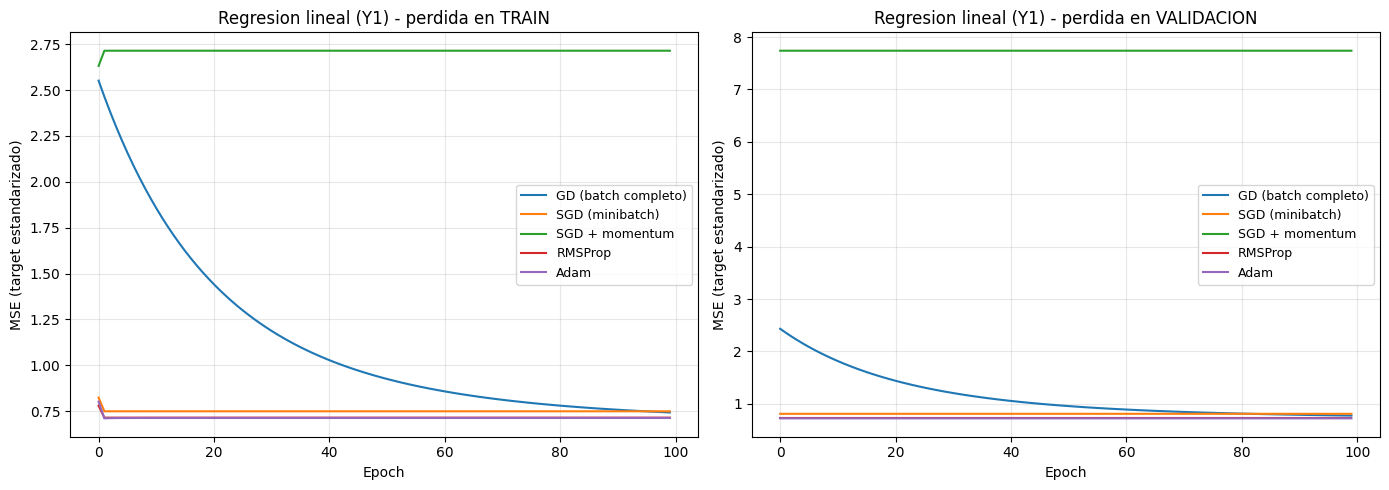

In [34]:
def graficar_convergencia(resultados, titulo, ylabel):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for nombre, info in resultados.items():
        h = info["history"]
        axes[0].plot(h["loss"], label=nombre)
        axes[1].plot(h["val_loss"], label=nombre)
    axes[0].set_title(f"{titulo} - perdida en TRAIN")
    axes[1].set_title(f"{titulo} - perdida en VALIDACION")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

graficar_convergencia(reg_resultados, "Regresion lineal (Y1)",
                      "MSE (target estandarizado)")

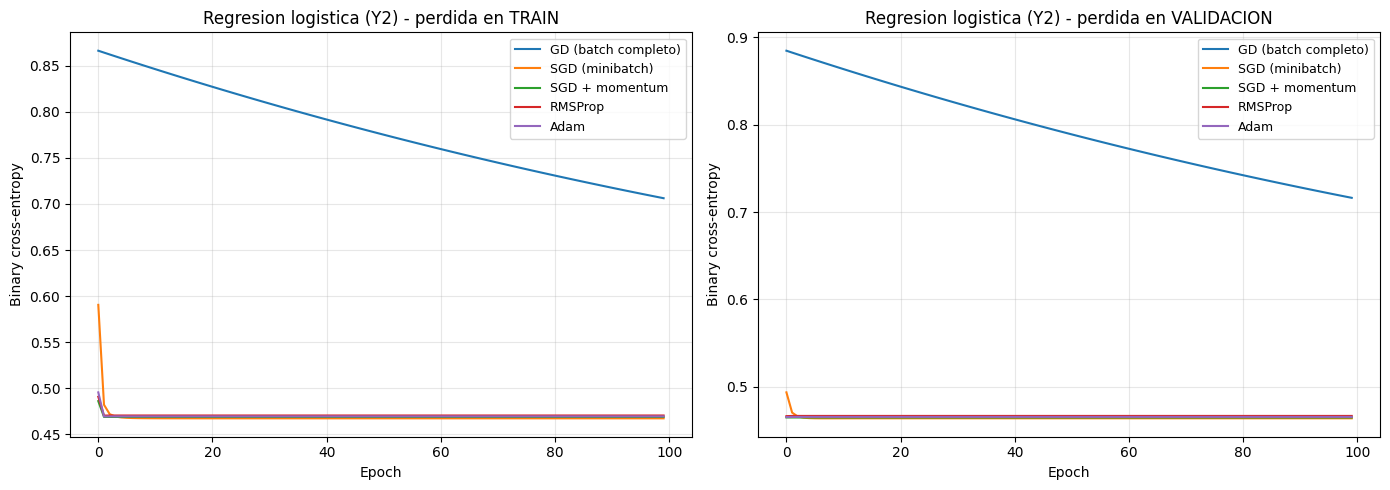

In [35]:
graficar_convergencia(clf_resultados, "Regresion logistica (Y2)",
                      "Binary cross-entropy")

## 12. Selección automática de los 2 mejores y evaluación en test

Para **cada tarea** se eligen automáticamente los 2 mejores optimizadores según validación
(regresión: menor RMSE; clasificación: mayor F1, con ROC-AUC como desempate) y **solo esos 2**
se evalúan en el conjunto de test.

In [36]:
# --- Seleccion automatica segun VALIDACION ---
mejores_reg = tabla_reg_val.sort_values("RMSE").index[:2].tolist()
mejores_clf = tabla_clf_val.sort_values(["F1", "ROC_AUC"], ascending=False).index[:2].tolist()
print("Regresion   - 2 mejores por VALIDACION (menor RMSE):", mejores_reg)
print("Clasificacion - 2 mejores por VALIDACION (mayor F1 / ROC-AUC):", mejores_clf)

# --- Evaluacion SOLO de esos 2 en TEST ---
filas_reg_test = []
for nombre in mejores_reg:
    rmse, mae, r2 = metricas_regresion(reg_resultados[nombre]["modelo"], X_test_s, y1_test.values)
    filas_reg_test.append({"optimizador": nombre, "RMSE": rmse, "MAE": mae, "R2": r2})
tabla_reg_test = pd.DataFrame(filas_reg_test).set_index("optimizador")

filas_clf_test = []
for nombre in mejores_clf:
    acc, f1, auc = metricas_clasificacion(clf_resultados[nombre]["modelo"], X_test_s, y2_test.values)
    filas_clf_test.append({"optimizador": nombre, "accuracy": acc, "F1": f1, "ROC_AUC": auc})
tabla_clf_test = pd.DataFrame(filas_clf_test).set_index("optimizador")

print("=== METRICAS EN TEST ===")
print("Regresion lineal (Y1) - TEST (escala NT$):")
display(tabla_reg_test)
print("Regresion logistica (Y2) - TEST:")
display(tabla_clf_test)

Regresion   - 2 mejores por VALIDACION (menor RMSE): ['Adam', 'RMSProp']
Clasificacion - 2 mejores por VALIDACION (mayor F1 / ROC-AUC): ['RMSProp', 'Adam']
=== METRICAS EN TEST ===
Regresion lineal (Y1) - TEST (escala NT$):


,RMSE,MAE,R2
optimizador,,,
Adam,"107,312.5953","83,010.0208",0.3192
RMSProp,"109,483.3307","83,430.6550",0.2914


Regresion logistica (Y2) - TEST:


,accuracy,F1,ROC_AUC
optimizador,,,
RMSProp,0.8140,0.3877,0.7087
Adam,0.8113,0.3716,0.7071


## 13. Análisis de resultados

### 13.1 Comparación de los optimizadores en validación

**Regresión lineal (Y1 = LIMIT_BAL).** Los métodos adaptativos lideran con claridad; el resto queda por detrás y, de forma notable, SGD+momentum diverge.

| Optimizador | RMSE (NT\$) | MAE (NT\$) | R² |
|---|---:|---:|---:|
| Adam | 109.812 | 84.193 | 0.312 |
| RMSProp | 109.910 | 84.141 | 0.311 |
| GD (batch completo) | 113.706 | 87.273 | 0.263 |
| SGD (minibatch) | 116.172 | 87.779 | 0.230 |
| SGD + momentum | 359.131 | 135.846 | **-6.356** |


- **Adam y RMSProp obtuvieron los mejores resultados**, con valores muy similares entre sí. Ambos alcanzaron un RMSE cercano a 109.800 y un R^2 aproximado de 0,31. Esto se debe a que ajustan la tasa de aprendizaje de forma adaptativa para cada parámetro, lo que favorece una convergencia más estable.

- **SGD con momentum tuvo un mal resultado**, porque no logró estabilizarse durante el entrenamiento. Con una tasa de aprendizaje de 0,01 y momentum beta = 0,9, el método avanzó con demasiado impulso y terminó alejándose del mínimo. Por eso, la pérdida aumentó mucho, obteniendo un R^2 negativo y un RMSE cercano a 359.000. Esto muestra que el momentum puede causar problemas si no se ajusta bien la tasa de aprendizaje.

- **Gradiente descendente batch y SGD minibatch tuvieron un rendimiento intermedio**. Sus valores de R^2 estuvieron entre 0,23 y 0,26 aproximadamente. La diferencia entre ambos no fue muy grande, ya que en regresión lineal el problema es convexo y, si los métodos logran converger, suelen llegar a resultados parecidos.

**Regresión logística (Y2 = default).** Aquí el patrón es mucho más nítido:

| Optimizador | Accuracy | F1 | ROC-AUC |
|---|---|---|---|
| RMSProp | 0.811 | 0.386 | 0.722 |
| Adam | 0.808 | 0.364 | 0.720 |
| SGD + momentum | 0.808 | 0.359 | 0.720 |
| SGD (minibatch) | 0.808 | 0.357 | 0.720 |
| GD (batch completo) | 0.558 | 0.303 | 0.514 |


- **RMSProp obtuvo el mejor resultado en clasificación**, especialmente según la métrica F1, con un valor de 0,386. Luego aparecen Adam, SGD con momentum y SGD, con resultados cercanos entre sí, alrededor de F1 ≈ 0,36 y AUC ≈ 0,72.

- ***GD (batch completo)** . Alcanzó una accuracy de 0,558 y un AUC de 0,514, valor muy cercano al azar. Esto indica que el modelo no logró separar correctamente las clases en 100 épocas. Al realizar solo una actualización de pesos por época, el método avanzó lentamente y no consiguió una buena convergencia.

- **La accuracy no es suficiente para evaluar este problema**, ya que las clases están desbalanceadas. Aproximadamente solo un 22% de los casos corresponde a incumplimiento, por lo que un modelo que siempre predijera “no default” obtendría una accuracy cercana al 78%. Por esta razón, la comparación se basó principalmente en F1 y ROC-AUC, que entregan una evaluación más adecuada del desempeño del clasificador.

- **Las curvas de convergencia confirman estos resultados**. Gradiente descendente batch disminuye la pérdida de forma lenta y se mantiene en valores altos. En cambio, SGD, RMSProp y Adam reducen la pérdida con mayor rapidez y luego se estabilizan. En el caso de SGD con momentum aplicado a regresión, la curva aumenta bruscamente, lo que evidencia un problema de divergencia.

### 13.2 Justificación de los 2 optimizadores elegidos por tarea

La selección es **automática** según validación (regresión: menor RMSE; clasificación: mayor F1, con ROC-AUC como desempate):

- **Regresión → Adam y RMSProp.** Son los de menor RMSE (109.812 y 109.910 NT$) y mayor R² (0.312 y 0.311), casi empatados. La selección automática descartó correctamente a SGD+momentum, que había divergido.
- **Clasificación → RMSProp y Adam.** Encabezan el F1 (0.386 y 0.364) con un ROC-AUC equivalente (~0.72).

En ambas tareas el patrón es consistente: **los métodos con tasa de aprendizaje adaptativa (RMSProp/Adam) dominan**, el **batch completo nunca entra en el top-2**, y el **momentum resulta poco fiable con estos hiperparámetros**. El grupo de cabeza en clasificación está algo más separado (RMSProp destaca), mientras que en regresión Adam y RMSProp están a escasos cientos de NT$ uno del otro.

### 13.3 Desempeño en el conjunto de test

Solo se evaluaron los 2 mejores por tarea:

| Tarea | Optimizador | Métricas en test |
|---|---|---|
| Regresión | Adam | RMSE 107.313 · MAE 83.010 · R² 0.319 |
| Regresión | RMSProp | RMSE 109.483 · MAE 83.431 · R² 0.291 |
| Clasificación | RMSProp | accuracy 0.814 · F1 0.388 · AUC 0.709 |
| Clasificación | Adam | accuracy 0.811 · F1 0.372 · AUC 0.707 |

- Las métricas de **test son muy parecidas a las de validación** (p. ej. Adam en regresión: R^2 0.312 en val vs 0.319 en test; RMSProp en clasificación: F1 0.386 en val vs 0.388 en test). La estabilidad val↔test indica **ausencia de sobreajuste**: los modelos lineales de una sola capa generalizan bien.
- En regresión, **Adam mantiene (incluso mejora ligeramente) la ventaja** sobre RMSProp también en test. En clasificación, **RMSProp conserva el mejor F1 y accuracy**, con Adam muy cerca.
- El **escalado sin fuga** (fit solo en train) y la **estratificación por Y2** aseguran que estas cifras de test sean una estimación honesta del rendimiento sobre datos nuevos.

## 14. Conclusiones

- **Los optimizadores adaptativos fueron los más efectivos.** RMSProp y Adam obtuvieron los mejores resultados tanto en regresión como en clasificación. Esto se debe a que ajustan la tasa de aprendizaje para cada parámetro, lo que ayuda a que el entrenamiento sea más rápido y estable.

- **El tamaño de lote afectó el rendimiento.** En clasificación, el gradiente descendente batch completo tuvo el peor desempeño, con resultados cercanos al azar. Esto ocurrió porque realiza solo una actualización de pesos por epoch, lo que no fue suficiente con una tasa de aprendizaje de 0,01 y 100 epochs. En regresión, esta desventaja fue menor, ya que el problema es convexo.

- **SGD con momentum tuvo problemas en regresión.** Este método no logró converger correctamente y obtuvo un R² negativo, junto con un RMSE cercano a 359.000. Esto ocurrió porque el momentum acumuló demasiado impulso y el modelo terminó sobrepasando la zona del mínimo. Aunque en clasificación funcionó mejor, los resultados muestran que este optimizador necesita ajustar cuidadosamente la tasa de aprendizaje.

- **Las métricas de clasificación fueron importantes por el desbalance de clases.** Como la clase de incumplimiento representa cerca del 22% de los casos, la accuracy podía ser engañosa. Un modelo que predijera siempre la clase mayoritaria podría obtener una accuracy alta sin ser realmente útil. Por eso, métricas como F1 y ROC-AUC fueron más adecuadas para comparar los modelos.

- **Los modelos generalizaron de forma adecuada.** Los resultados en prueba fueron similares a los obtenidos en validación, por lo que no se observaron señales importantes de sobreajuste. Esto se relaciona con el uso de un preprocesamiento sin fuga de información, una división estratificada de los datos y modelos simples.

- **El desempeño general todavía tiene limitaciones.** El R^2 cercano a 0,31 en regresión y el F1 cercano a 0,38 en clasificación muestran que las variables utilizadas y los modelos lineales solo explican una parte del problema. Para mejorar los resultados, se podrían agregar más variables, ajustar el umbral de decisión, tratar el desbalance de clases, aumentar los epochs, probar otras tasas de aprendizaje o usar modelos no lineales. Aun así, para comparar los optimizadores de forma justa, fue correcto mantener los mismos hiperparámetros en todos los casos.

##Uso de Ia
se utilizo deepseek para la solucion de errores y recomendacion del dataset